# Biblioteki

In [1]:
%pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.2 MB/s eta 0:00:00 0:00:01


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from tensorflow.keras.models import Sequential # type: ignore
from tensorflow.keras.layers import Dense, Dropout, Input # type: ignore
from tensorflow.keras.optimizers import Adam # type: ignore
from tensorflow.keras.callbacks import EarlyStopping # type: ignore
from tensorflow.keras.backend import clear_session # type: ignore
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Przygotowanie danych

In [4]:
def read_currency_data(filepath: str, start_date: str):
    """
    reads file and cuts the unnecessary data: League and Confidence.
    Date is changed into day of the league, to transform date into number.
    returns DataFrame
    """
    df = pd.read_csv(filepath, sep=';', skipinitialspace=True)
    df['Date'] = pd.to_datetime(df['Date'])
    df = df[df['Pay'] == 'Chaos Orb']
    df['Day of league'] = (df['Date'] - pd.to_datetime(start_date)).dt.days + 1
    columns_to_drop = ['League', 'Date', 'Pay', 'Confidence']
    df = df.drop(columns=columns_to_drop)
    df = df.reset_index(drop=True)
    return df

def transform_currency_data(df):
    """
    Drop with all NaN
    Drop with 5 NaN's in Row - bad data
    Fill NaN's with data from day before, and fill first day's
    Cuts data to 100 days (Settlers is too large)
    returns DataFrame
    """
    df = df.pivot(index='Day of league', columns='Get', values='Value')
    df = df.dropna(axis=1, how='all')
    df = df.dropna(axis=1, thresh=len(df) - 4)
    df = df.ffill().bfill()
    df = df[df.index <= 100]
    return df.T
keepers_df = transform_currency_data(read_currency_data('data/Keepers.currency.csv', '2025-10-31'))
mercenaries_df = transform_currency_data(read_currency_data('data/Mercenaries.currency.csv', '2025-06-13'))
settlers_df = transform_currency_data(read_currency_data('data/Settlers.currency.csv', '2024-07-26'))
affiliction_df = transform_currency_data(read_currency_data('data/Affliction.currency.csv', '2023-12-08'))
necropolis_df = transform_currency_data(read_currency_data('data/Necropolis.currency.csv', '2024-03-29'))

In [ ]:
ITEM = "Divine Orb"
WINDOW = 14
TEST_LIGA = -1
leagues = [necropolis_df, affiliction_df, settlers_df, mercenaries_df, keepers_df]
test_idx = TEST_LIGA % len(leagues)
contamination = 0.1

tscv = TimeSeriesSplit()


# Wykrywanie anomalii za pomocą IQR

Necropolis: 1 anomalii na 100 dni (1.0%)
Affliction: 0 anomalii na 100 dni (0.0%)
Settlers: 3 anomalii na 100 dni (3.0%)
Mercenaries: 0 anomalii na 100 dni (0.0%)
Keepers: 3 anomalii na 100 dni (3.0%)


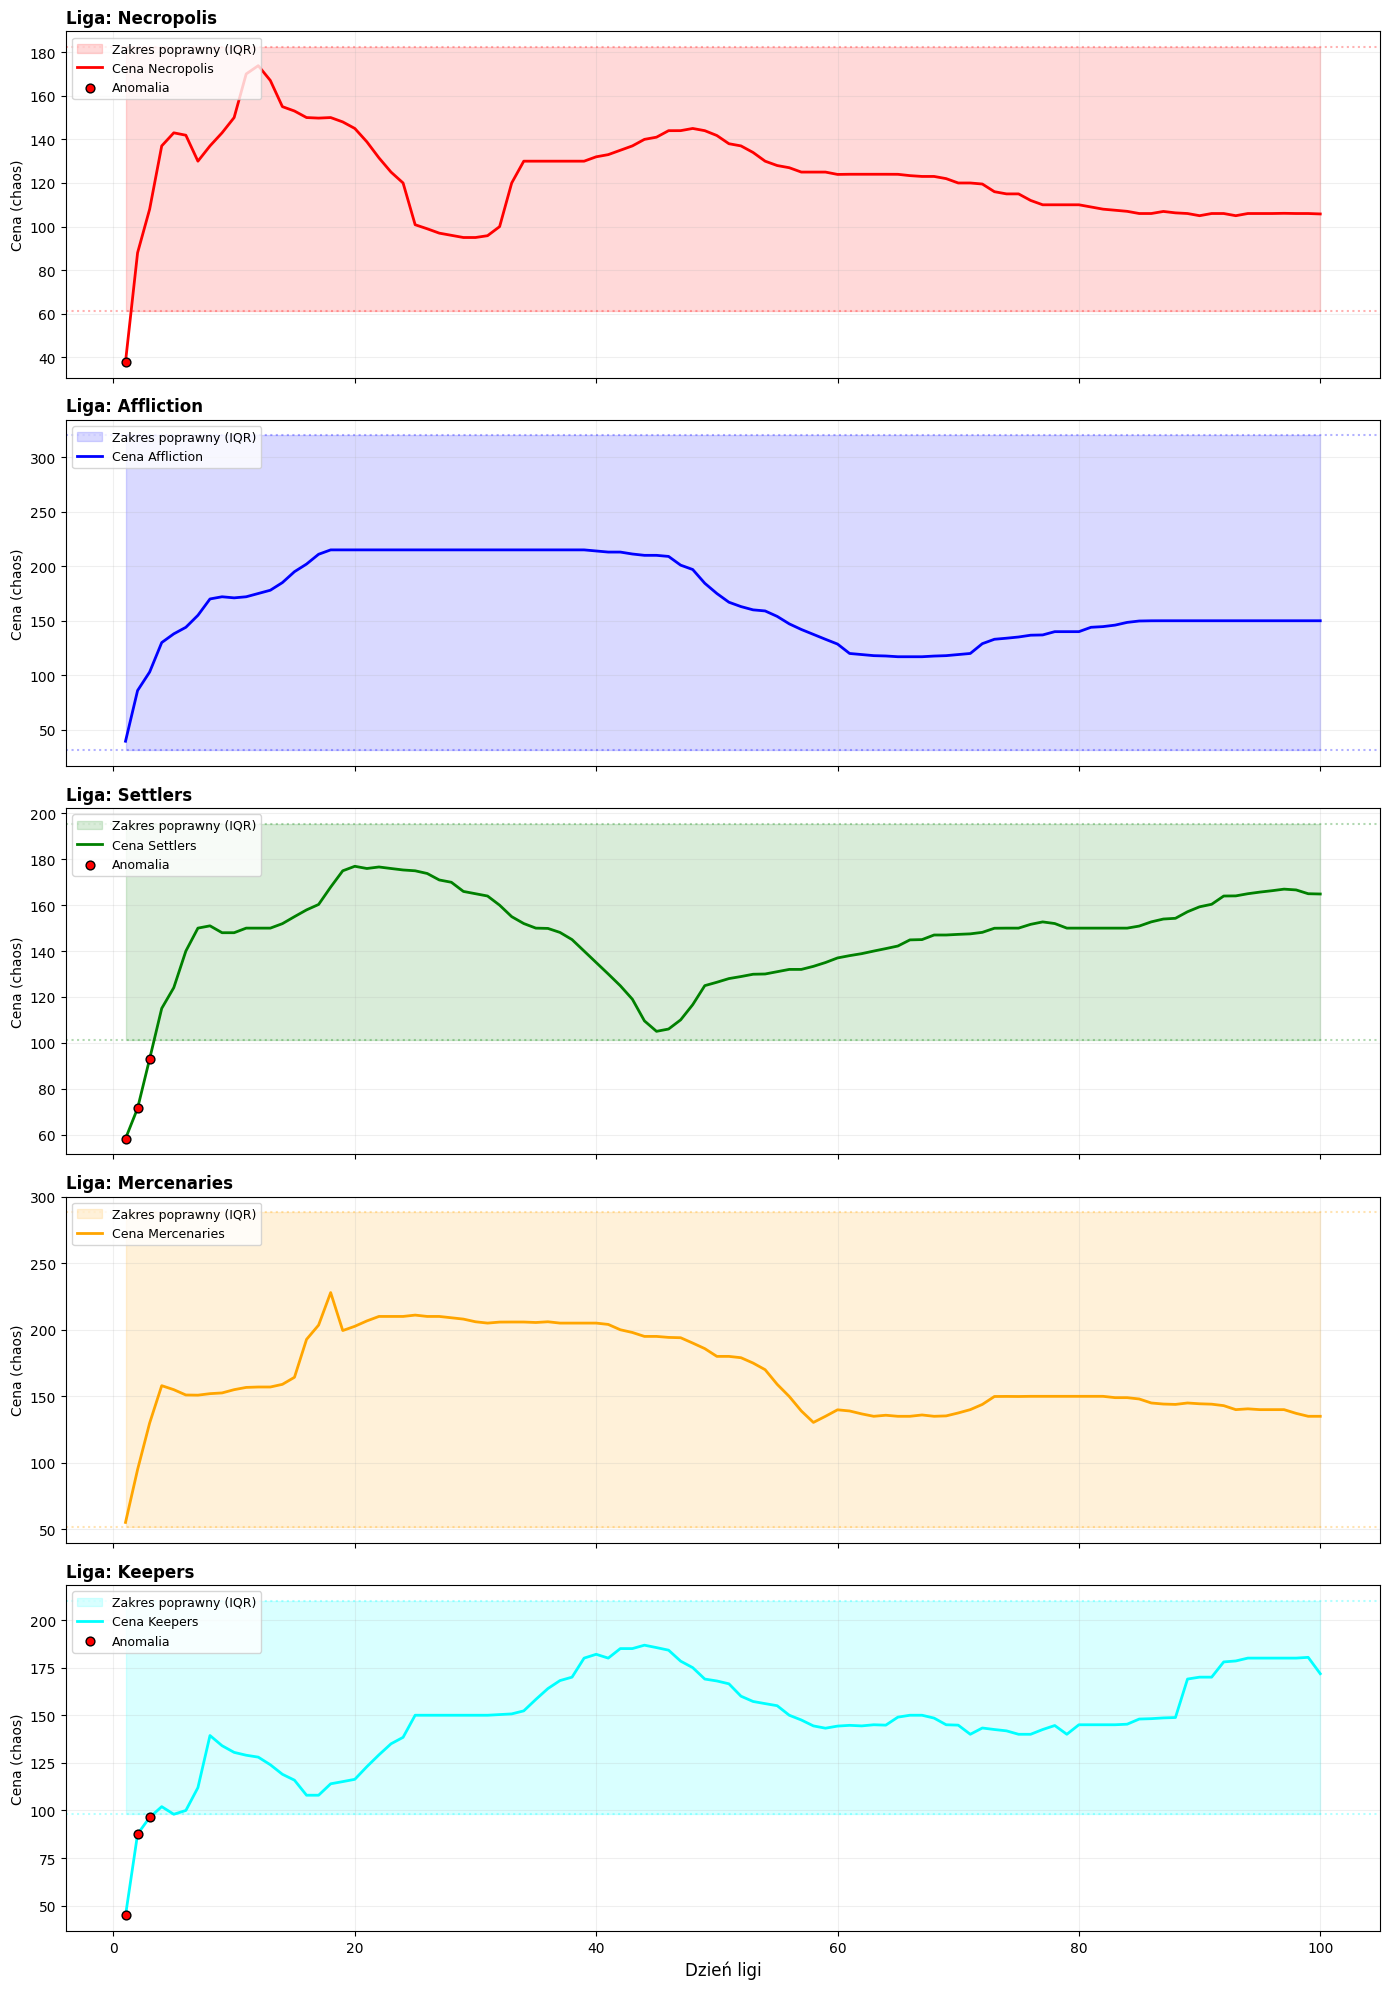

In [14]:
def detect_anomalies_iqr(series, threshold=1.5):
    """Wykrywanie anomalii metodą IQR"""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - threshold * iqr
    upper_bound = q3 + threshold * iqr
    anomalies = (series < lower_bound) | (series > upper_bound)
    return anomalies, lower_bound, upper_bound

all_anomalies = {}
league_names = ['Necropolis', 'Affliction', 'Settlers', 'Mercenaries', 'Keepers']
for i, (name, df) in enumerate(zip(league_names, leagues)):
    if ITEM in df.index:
        prices = df.loc[ITEM].dropna()
        anomalies, lb, ub = detect_anomalies_iqr(prices)
        n_anomalies = anomalies.sum()
        print(f"{name}: {n_anomalies} anomalii na {len(prices)} dni ({n_anomalies/len(prices)*100:.1f}%)")
        all_anomalies[name] = prices[anomalies].tolist()

# Ustalenie liczby lig do wyświetlenia
leagues_to_plot = [(name, df) for name, df in zip(league_names, leagues) if ITEM in df.index]
n_leagues = len(leagues_to_plot)

# Tworzenie siatki wykresów (n wierszy, 1 kolumna)
fig, axes = plt.subplots(n_leagues, 1, figsize=(14, 4 * n_leagues), sharex=True)

# Jeśli jest tylko jedna liga, Matplotlib nie zwróci tablicy, więc ją wymuszamy
if n_leagues == 1:
    axes = [axes]

colors = ['red', 'blue', 'green', 'orange', 'cyan']

for i, (name, df) in enumerate(leagues_to_plot):
    prices = df.loc[ITEM].dropna()
    anomalies, lb, ub = detect_anomalies_iqr(prices)
    ax = axes[i]
    
    # 1. Cieniowanie zakresu IQR
    ax.fill_between(prices.index, lb, ub, color=colors[i], alpha=0.15, 
                    label=f'Zakres poprawny (IQR)')
    
    # 2. Linie graniczne (opcjonalnie, dla większej wyraźności)
    ax.axhline(y=lb, color=colors[i], linestyle=':', alpha=0.3)
    ax.axhline(y=ub, color=colors[i], linestyle=':', alpha=0.3)
    
    # 3. Główna linia ceny
    ax.plot(prices.index, prices.values, color=colors[i], lw=2, label=f'Cena {name}')
    
    # 4. Zaznaczenie anomalii
    if anomalies.any():
        ax.scatter(prices.index[anomalies], prices[anomalies], 
                   color='red', s=40, edgecolors='black', zorder=5, label='Anomalia')
    
    # Stylizacja pojedynczego wykresu
    ax.set_title(f'Liga: {name}', loc='left', fontsize=12, fontweight='bold')
    ax.set_ylabel('Cena (chaos)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(alpha=0.2)

# Wspólna etykieta osi X na samym dole
plt.xlabel('Dzień ligi', fontsize=12)
plt.tight_layout()
plt.show()

## Wykrywanie anomalii za pomocą 


## Wykrywanie anomalii za pomocą 


## Wykrywanie anomalii za pomocą 


## Wykrywanie anomalii za pomocą 


In [8]:
def normalize(series):
    base = series.iloc[0]
    if base == 0 or pd.isna(base):
        return None
    return series / base

def make_windows(series, window):
    X, y = [], []
    for i in range(window, len(series)):
        X.append(series.iloc[i-window:i].values)
        y.append(series.iloc[i])
    return np.array(X), np.array(y)

X_train_list, y_train_list = [], []
for i, df in enumerate(leagues):
    if i == test_idx:
        continue
    if ITEM not in df.index:
        continue

    # Pobranie surowego szeregu (ceny)
    raw_series = df.loc[ITEM].dropna()

    # Normalizacja
    norm = normalize(raw_series)
    if norm is None:
        continue

    # Tworzenie okien
    X, y = make_windows(norm, WINDOW)

    X_train_list.append(X)
    y_train_list.append(y)

X_train = np.vstack(X_train_list)
y_train = np.concatenate(y_train_list)
print(f"Dane treningowe: {X_train.shape}")

print(X_train)

scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()
X_train_minmax = scaler_minmax.fit_transform(X_train)
X_train_standard = scaler_standard.fit_transform(X_train)

df_test = leagues[test_idx]
raw_test = df_test.loc[ITEM].dropna()
norm_test = normalize(raw_test)
base_price = raw_test.iloc[0]
initial_window = norm_test.iloc[:WINDOW].values

Dane treningowe: (344, 14)
[[1.         2.31578947 2.84210526 ... 4.57355263 4.39473684 4.07894737]
 [2.31578947 2.84210526 3.60526316 ... 4.39473684 4.07894737 4.02631579]
 [2.84210526 3.60526316 3.76315789 ... 4.07894737 4.02631579 3.94736842]
 ...
 [2.69439421 2.67631103 2.62206148 ... 2.53164557 2.53164557 2.53164557]
 [2.67631103 2.62206148 2.60759494 ... 2.53164557 2.53164557 2.48101266]
 [2.62206148 2.60759494 2.60262206 ... 2.53164557 2.48101266 2.44122966]]


In [23]:
def clean_with_detector(X, y, detector, detector_name):
    """
    Usuwa obserwacje uznane za odstające przez detektor.
    Zwraca oczyszczone X i y.
    """
    if detector_name == 'LOF':
        labels = detector.fit_predict(X)
    else:
        detector.fit(X)
        labels = detector.predict(X)
    
    inlier_mask = labels == 1
    X_clean = X[inlier_mask]
    y_clean = y[inlier_mask]
    removed = np.sum(~inlier_mask)
    print(f"{detector_name}: usunięto {removed} próbek, pozostało {len(X_clean)}")
    return X_clean, y_clean

detectors = {
    'IsolationForest': IsolationForest(contamination=contamination, random_state=42),
    'OneClassSVM': OneClassSVM(nu=contamination, kernel='rbf', gamma='scale'),
    'LOF': LocalOutlierFactor(n_neighbors=20, contamination=contamination, novelty=False),
    'EllipticEnvelope': EllipticEnvelope(contamination=contamination, random_state=42)
}

cleaned_data = {} 

for name, detector in detectors.items():
    X_clean, y_clean = clean_with_detector(X_train_standard, y_train, detector, name)
    cleaned_data[name] = (X_clean, y_clean)

cleaned_data['original_data'] = (X_train_standard, y_train)
print(cleaned_data['original_data'])

IsolationForest: usunięto 35 próbek, pozostało 309
OneClassSVM: usunięto 41 próbek, pozostało 303
LOF: usunięto 35 próbek, pozostało 309
EllipticEnvelope: usunięto 35 próbek, pozostało 309
(array([[-2.43127652, -1.08545443, -0.52517838, ...,  1.45652779,
         1.26659146,  0.91693855],
       [-1.02519407, -0.50382338,  0.32989042, ...,  1.25282324,
         0.90527186,  0.85648763],
       [-0.46276109,  0.33954165,  0.50680121, ...,  0.8930801 ,
         0.84505192,  0.76581125],
       ...,
       [-0.62060847, -0.68704242, -0.77172313, ..., -0.86958538,
        -0.86511796, -0.86024203],
       [-0.63993257, -0.74699354, -0.78793196, ..., -0.86958538,
        -0.86511796, -0.91839735],
       [-0.69790486, -0.76298051, -0.79350374, ..., -0.86958538,
        -0.92305106, -0.96409082]]), array([4.02631579, 3.94736842, 3.94078947, 3.94736842, 3.89473684,
       3.81578947, 3.65460526, 3.46101974, 3.28947368, 3.15789474,
       2.65413526, 2.60526316, 2.55263158, 2.52631579, 2.5    

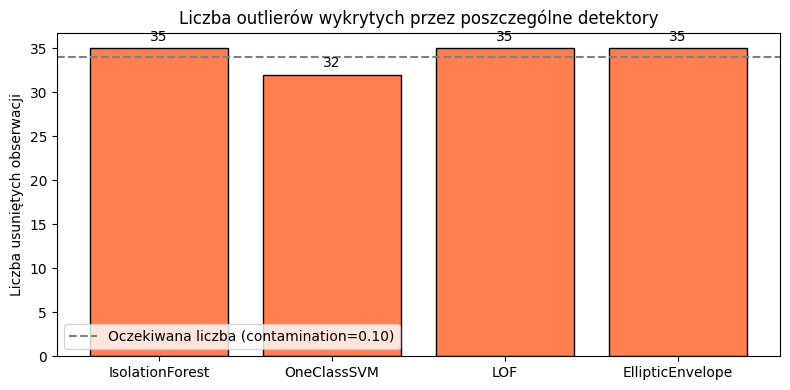

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

removed_counts = [np.sum(~np.isin(X_train_standard, X_clean).all(axis=1)) 
                  if X_train_standard.shape[0] != X_clean.shape[0] 
                  else (X_train_standard.shape[0] - len(X_clean)) 
                  for X_clean, _ in cleaned_data.values()]

fig, ax = plt.subplots(figsize=(8, 4))
detector_names = list(cleaned_data.keys())
bars = ax.bar(detector_names, removed_counts, color='coral', edgecolor='black')
ax.set_ylabel('Liczba usuniętych obserwacji')
ax.set_title('Liczba outlierów wykrytych przez poszczególne detektory')
for bar, count in zip(bars, removed_counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, str(count),
            ha='center', va='bottom')
ax.axhline(y=int(contamination * len(X_train_standard)), color='gray', linestyle='--',
           label=f'Oczekiwana liczba (contamination={contamination:.2f})')
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
def forecast_regression(model, initial_window, full_series_norm, base_price, use_scaler=False, scaler=None):
    window = len(initial_window)
    buf = list(initial_window)
    preds_norm = []
    for t in range(window, len(full_series_norm)):
        x_raw = np.array(buf[-window:]).reshape(1, -1)
        if use_scaler and scaler:
            x = scaler.transform(x_raw)
        else:
            x = x_raw
        pred = model.predict(x)[0]
        preds_norm.append(pred)
        buf.append(full_series_norm.iloc[t])
    preds = np.array(preds_norm) * base_price
    actuals = full_series_norm.iloc[window:].values * base_price
    return actuals, preds

# Regresja Liniowa

In [17]:
lr = LinearRegression()
lr.fit(X_train, y_train)
actuals_lr, preds_lr = forecast_regression(lr, initial_window, norm_test, base_price)
mae_lr = mean_absolute_error(actuals_lr, preds_lr)
mape_lr = mean_absolute_percentage_error(actuals_lr, preds_lr) * 100
print(f"LinearRegression -> MAE: {mae_lr:.2f}, MAPE: {mape_lr:.1f}%")

LinearRegression -> MAE: 2.62, MAPE: 1.7%


# Random Forest

In [18]:
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_grid = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train, y_train)

print(f"RF najlepsze parametry: {rf_grid.best_params_}")
print(f"RF najlepszy MAE (CV): {-rf_grid.best_score_:.4f}")

rf_best = rf_grid.best_estimator_
actuals_rf, preds_rf = forecast_regression(rf_best, initial_window, norm_test, base_price)
mae_rf = mean_absolute_error(actuals_rf, preds_rf)
mape_rf = mean_absolute_percentage_error(actuals_rf, preds_rf) * 100
print(f"RandomForest -> MAE: {mae_rf:.2f}, MAPE: {mape_rf:.1f}%")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
RF najlepsze parametry: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
RF najlepszy MAE (CV): 0.3289
RandomForest -> MAE: 4.06, MAPE: 2.6%


In [25]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
results = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    X_train, y_train = data

    rf_param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [5, 10],
        'min_samples_leaf': [2, 4]
    }

    
    rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
    rf_grid = GridSearchCV(
        estimator=rf_base,
        param_grid=rf_param_grid,
        cv=tscv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )
    rf_grid.fit(X_train, y_train)
    
    rf_best = rf_grid.best_estimator_
    actuals_rf, preds_rf = forecast_regression(rf_best, initial_window, norm_test, base_price)
    
    mae_rf = mean_absolute_error(actuals_rf, preds_rf)
    mape_rf = mean_absolute_percentage_error(actuals_rf, preds_rf) * 100
    mse_rf = mean_squared_error(actuals_rf, preds_rf)
    r2_rf = r2_score(actuals_rf, preds_rf)
    
    results[method_name] = {
        'MAE': mae_rf,
        'MAPE': mape_rf,
        'MSE': mse_rf,
        'R2': r2_rf,
        'best_params': rf_grid.best_params_
    }
    
    print(f"  MAE:  {mae_rf:.2f}")
    print(f"  MAPE: {mape_rf:.2f}%")
    print(f"  MSE:  {mse_rf:.2f}")
    print(f"  R²:   {r2_rf:.4f}")
    print(f"  best_params: {rf_grid.best_params_}")


Przetwarzanie danych: IsolationForest
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  89.86
  MAPE: 60.96%
  MSE:  8420.50
  R²:   -22.3635

Przetwarzanie danych: OneClassSVM
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  86.73
  MAPE: 58.96%
  MSE:  7890.60
  R²:   -20.8932

Przetwarzanie danych: LOF
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  89.89
  MAPE: 60.99%
  MSE:  8430.48
  R²:   -22.3912

Przetwarzanie danych: EllipticEnvelope
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  90.02
  MAPE: 61.10%
  MSE:  8459.86
  R²:   -22.4727

Przetwarzanie danych: original_data
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  90.08
  MAPE: 61.13%
  MSE:  8470.08
  R²:   -22.5010


In [26]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
results_svr = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    svr_param_grid = {
        'kernel': ['rbf', 'linear'],
        'C': [1, 10, 100],
        'epsilon': [0.05, 0.1],
        'gamma': ['scale', 0.1, 1]
    }

    X_train, y_train = data
    
    svr_base = SVR()
    svr_grid = GridSearchCV(
        estimator=svr_base,
        param_grid=svr_param_grid,
        cv=tscv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )
    svr_grid.fit(X_train, y_train)
    
    svr_best = svr_grid.best_estimator_
    actuals_svr, preds_svr = forecast_regression(
        svr_best, initial_window, norm_test, base_price,
        use_scaler=True, scaler=scaler_standard
    )
    
    mae_svr = mean_absolute_error(actuals_svr, preds_svr)
    mape_svr = mean_absolute_percentage_error(actuals_svr, preds_svr) * 100
    mse_svr = mean_squared_error(actuals_svr, preds_svr)
    r2_svr = r2_score(actuals_svr, preds_svr)
    
    results_svr[method_name] = {
        'MAE': mae_svr,
        'MAPE': mape_svr,
        'MSE': mse_svr,
        'R2': r2_svr,
        'best_params': svr_grid.best_params_
    }
    
    print(f"  MAE:  {mae_svr:.2f}")
    print(f"  MAPE: {mape_svr:.2f}%")
    print(f"  MSE:  {mse_svr:.2f}")
    print(f"  R²:   {r2_svr:.4f}")
    print(f"  best params: {svr_grid.best_params_}")


Przetwarzanie danych: IsolationForest
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.68
  MAPE: 1.77%
  MSE:  16.14
  R²:   0.9552
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: OneClassSVM
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.80
  MAPE: 1.84%
  MSE:  17.46
  R²:   0.9516
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: LOF
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.56
  MAPE: 1.68%
  MSE:  15.25
  R²:   0.9577
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: EllipticEnvelope
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.83
  MAPE: 1.86%
  MSE:  17.51
  R²:   0.9514
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: original_data
Fitting 5 folds for each o

In [19]:
svr_param_grid = {
    'kernel': ['rbf', 'linear'],
    'C': [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.05, 0.1, 0.2],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

svr_base = SVR()
svr_grid = GridSearchCV(
    estimator=svr_base,
    param_grid=svr_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)
svr_grid.fit(X_train_standard, y_train)

print(f"SVR najlepsze parametry: {svr_grid.best_params_}")
print(f"SVR najlepszy MAE (CV): {-svr_grid.best_score_:.4f}")

svr_best = svr_grid.best_estimator_
actuals_svr, preds_svr = forecast_regression(
    svr_best, initial_window, norm_test, base_price,
    use_scaler=True, scaler=scaler_standard
)
mae_svr = mean_absolute_error(actuals_svr, preds_svr)
mape_svr = mean_absolute_percentage_error(actuals_svr, preds_svr) * 100
print(f"SVR -> MAE: {mae_svr:.2f}, MAPE: {mape_svr:.1f}%")

Fitting 5 folds for each of 160 candidates, totalling 800 fits
SVR najlepsze parametry: {'C': 10, 'epsilon': 0.01, 'gamma': 'scale', 'kernel': 'linear'}
SVR najlepszy MAE (CV): 0.0517
SVR -> MAE: 2.63, MAPE: 1.7%


# KNN

In [20]:
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'p': [1, 2],  # 1 = Manhattan, 2 = Euclidean
    'algorithm': ['auto', 'ball_tree', 'kd_tree']
}

knn_base = KNeighborsRegressor()
knn_grid = GridSearchCV(
    estimator=knn_base,
    param_grid=knn_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)
knn_grid.fit(X_train_standard, y_train)

print(f"KNN najlepsze parametry: {knn_grid.best_params_}")
print(f"KNN najlepszy MAE (CV): {-knn_grid.best_score_:.4f}")

knn_best = knn_grid.best_estimator_
actuals_knn, preds_knn = forecast_regression(
    knn_best, initial_window, norm_test, base_price,
    use_scaler=True, scaler=scaler_standard
)
mae_knn = mean_absolute_error(actuals_knn, preds_knn)
mape_knn = mean_absolute_percentage_error(actuals_knn, preds_knn) * 100
print(f"KNN -> MAE: {mae_knn:.2f}, MAPE: {mape_knn:.1f}%")

Fitting 5 folds for each of 72 candidates, totalling 360 fits
KNN najlepsze parametry: {'algorithm': 'auto', 'n_neighbors': 7, 'p': 2, 'weights': 'uniform'}
KNN najlepszy MAE (CV): 0.4218
KNN -> MAE: 7.44, MAPE: 4.8%


# Sieć neuronowa

In [28]:
def build_nn_model(hidden_layers=2, neurons=64, dropout_rate=0.3, learning_rate=0.001, act=['relu']):
    model = Sequential()
    model.add(Input(shape=(WINDOW,)))
    
    first_act = act[0] if len(act) > 0 else 'relu'
    model.add(Dense(neurons, activation=first_act))
    model.add(Dropout(dropout_rate))
    
    for i in range(hidden_layers - 1):
        if i + 1 < len(act):
            current_act = act[i + 1]
        else:
            current_act = act[-1]
            
        model.add(Dense(neurons // 2, activation=current_act))
        model.add(Dropout(dropout_rate))
    
    model.add(Dense(1))
    
    model.compile(
        optimizer=Adam(learning_rate=learning_rate), 
        loss='mse', 
        metrics=['mae']
    )
    return model

nn_configs = [
    {'hidden_layers': 5, 'neurons': 8, 'dropout': 0.3, 'lr': 0.001, 'act': ['relu', 'elu']},
    {'hidden_layers': 7, 'neurons': 16, 'dropout': 0.2, 'lr': 0.001, 'act': ['elu', 'elu']},
    {'hidden_layers': 5, 'neurons': 64, 'dropout': 0.3, 'lr': 0.0005, 'act': ['relu', 'leaky_relu', 'tanh']},
    {'hidden_layers': 10, 'neurons': 32, 'dropout': 0.2, 'lr': 0.001, 'act': ['relu']},
]

best_nn_mae = float('inf')
best_nn_config = None
best_nn_model = None

for config in nn_configs:
    clear_session()
    print(f"Testowanie: {config}")
    nn_model = build_nn_model(
        hidden_layers=config['hidden_layers'],
        neurons=config['neurons'],
        dropout_rate=config['dropout'],
        learning_rate=config['lr'],
        act=config['act']
    )
    early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    
    nn_model.fit(
        X_train_minmax, y_train,
        epochs=150, batch_size=32, validation_split=0.1,
        callbacks=[early_stop], verbose=0
    )
    
    val_preds = nn_model.predict(X_train_minmax[-100:], verbose=0)
    val_mae = mean_absolute_error(y_train[-100:], val_preds.flatten())
    print(f"  Val MAE: {val_mae:.4f}")
    
    if val_mae < best_nn_mae:
        best_nn_mae = val_mae
        best_nn_config = config
        best_nn_model = nn_model

print(f"\nNajlepsza konfiguracja NN: {best_nn_config}")

def forecast_nn(model, scaler, initial_window_norm, full_series_norm, base_price):
    window = len(initial_window_norm)
    buf = list(initial_window_norm)
    preds_norm = []
    for t in range(window, len(full_series_norm)):
        x_raw = np.array(buf[-window:]).reshape(1, -1)
        x_scaled = scaler.transform(x_raw)
        pred = model.predict(x_scaled, verbose=0)[0, 0]
        preds_norm.append(pred)
        buf.append(full_series_norm.iloc[t])
    preds = np.array(preds_norm) * base_price
    actuals = full_series_norm.iloc[window:].values * base_price
    return actuals, preds

actuals_nn, preds_nn = forecast_nn(best_nn_model, scaler_minmax, initial_window, norm_test, base_price)
mae_nn = mean_absolute_error(actuals_nn, preds_nn)
mape_nn = mean_absolute_percentage_error(actuals_nn, preds_nn) * 100
print(f"Sieć neuronowa -> MAE: {mae_nn:.2f}, MAPE: {mape_nn:.1f}%")


Testowanie: {'hidden_layers': 5, 'neurons': 8, 'dropout': 0.3, 'lr': 0.001, 'act': ['relu', 'elu']}
  Val MAE: 0.4061
Testowanie: {'hidden_layers': 7, 'neurons': 16, 'dropout': 0.2, 'lr': 0.001, 'act': ['elu', 'elu']}
  Val MAE: 0.3059
Testowanie: {'hidden_layers': 5, 'neurons': 64, 'dropout': 0.3, 'lr': 0.0005, 'act': ['relu', 'leaky_relu', 'tanh']}
  Val MAE: 0.2662
Testowanie: {'hidden_layers': 10, 'neurons': 32, 'dropout': 0.2, 'lr': 0.001, 'act': ['relu']}
  Val MAE: 0.4062

Najlepsza konfiguracja NN: {'hidden_layers': 5, 'neurons': 64, 'dropout': 0.3, 'lr': 0.0005, 'act': ['relu', 'leaky_relu', 'tanh']}
Sieć neuronowa -> MAE: 11.32, MAPE: 7.4%


# Naiwny

In [22]:
naive_preds = actuals_nn[:-1]
naive_mape = mean_absolute_percentage_error(actuals_nn[1:], naive_preds) * 100
print(f"\nNaiwny (jutro=today) MAPE: {naive_mape:.1f}%")


Naiwny (jutro=today) MAPE: 1.7%


# System Ekspercki


SYMULACJA SYSTEMU EKSPERCKIEGO – Divine Orb
Liga testowa: Keepers
Dni: 15 → 100

Dzień  Cena         Prognoza     Wartość    Decyzja   
--------------------------------------------------
15     115.90       110.33       0.00       TRZYMAJ   
16     108.00       115.41       -0.00      TRZYMAJ   
17     108.00       116.86       0.00       TRZYMAJ   
18     114.00       117.70       0.00       TRZYMAJ   
19     115.15       118.55       0.00       TRZYMAJ   
20     116.35       119.78       0.00       TRZYMAJ   
21     123.00       120.95       0.00       TRZYMAJ   
22     129.20       121.73       0.00       TRZYMAJ   
23     135.00       121.01       0.00       TRZYMAJ   
24     138.40       121.08       0.00       TRZYMAJ   
25     150.00       121.64       0.00       TRZYMAJ   
26     150.00       123.14       0.00       TRZYMAJ   
27     150.00       124.71       0.00       TRZYMAJ   
28     150.00       126.57       0.00       TRZYMAJ   
29     150.00       128.79       0.00     

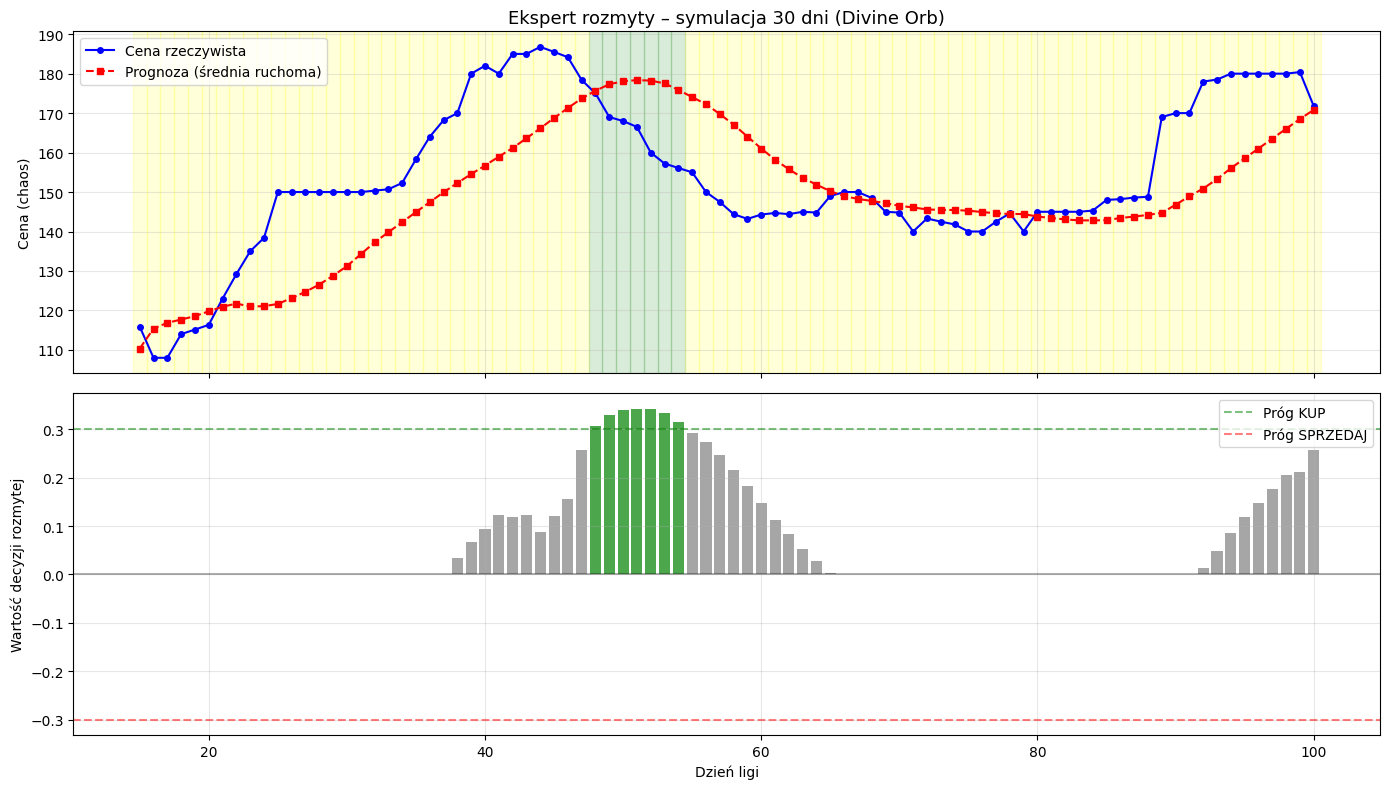

In [27]:
def build_fuzzy_expert():
    cena_universe = np.arange(0, 301, 1)
    prognoza_universe = np.arange(0, 301, 1)

    cena = ctrl.Antecedent(cena_universe, 'cena')
    prognoza = ctrl.Antecedent(prognoza_universe, 'prognoza')
    decyzja = ctrl.Consequent(np.arange(-1, 1.01, 0.01), 'decyzja')

    cena['niska'] = fuzz.trimf(cena.universe, [0, 0, 100])
    cena['srednia'] = fuzz.trimf(cena.universe, [70, 130, 190])
    cena['wysoka'] = fuzz.trimf(cena.universe, [150, 250, 300])

    prognoza['spadnie'] = fuzz.trimf(prognoza.universe, [0, 0, 100])
    prognoza['stabilna'] = fuzz.trimf(prognoza.universe, [80, 140, 200])
    prognoza['wzrosnie'] = fuzz.trimf(prognoza.universe, [150, 250, 300])

    decyzja['sprzedaj'] = fuzz.trimf(decyzja.universe, [-1, -1, -0.2])
    decyzja['trzymaj'] = fuzz.trimf(decyzja.universe, [-0.3, 0, 0.3])
    decyzja['kup'] = fuzz.trimf(decyzja.universe, [0.2, 1, 1])

    rules = [
        ctrl.Rule(cena['niska'] & prognoza['wzrosnie'], decyzja['kup']),
        ctrl.Rule(cena['wysoka'] & prognoza['spadnie'], decyzja['sprzedaj']),
        ctrl.Rule(prognoza['stabilna'], decyzja['trzymaj']),
        ctrl.Rule(cena['srednia'] & prognoza['wzrosnie'], decyzja['kup']),
        ctrl.Rule(cena['niska'] & prognoza['spadnie'], decyzja['trzymaj']),
        ctrl.Rule(cena['wysoka'] & ~prognoza['spadnie'], decyzja['trzymaj']),
    ]

    expert_ctrl = ctrl.ControlSystem(rules)
    return ctrl.ControlSystemSimulation(expert_ctrl)


test_raw = leagues[test_idx].loc[ITEM].dropna()
prices = test_raw.values

simulation_days = 86
start_day = WINDOW 
end_day = min(start_day + simulation_days, len(prices))

print(f"\n{'='*60}")
print(f"SYMULACJA SYSTEMU EKSPERCKIEGO – {ITEM}")
print(
    f"Liga testowa: {['Necropolis', 'Affliction', 'Settlers', 'Mercenaries', 'Keepers'][test_idx]}")
print(f"Dni: {start_day+1} → {end_day}")
print(f"{'='*60}")

decisions_log = []
for t in range(start_day, end_day):
    current_price = prices[t]
    historical_window = prices[t - WINDOW:t]
    prognoza_value = historical_window.mean()

    expert = build_fuzzy_expert()
    expert.input['cena'] = current_price
    expert.input['prognoza'] = prognoza_value

    try:
        expert.compute()
        decision_value = expert.output['decyzja']
    except (KeyError, ValueError):
        decision_value = 0.0

    # Interpretacja wyniku
    if decision_value > 0.3:
        decision_text = "KUP"
    elif decision_value < -0.3:
        decision_text = "SPRZEDAJ"
    else:
        decision_text = "TRZYMAJ"

    decisions_log.append(
        (t + 1, current_price, prognoza_value, decision_value, decision_text))

print(f"\n{'Dzień':<6} {'Cena':<12} {'Prognoza':<12} {'Wartość':<10} {'Decyzja':<10}")
print("-" * 50)
for day, price, prog, val, dec in decisions_log:
    print(f"{day:<6} {price:<12.2f} {prog:<12.2f} {val:<10.2f} {dec:<10}")

decisions_array = np.array([d[4] for d in decisions_log])
unique, counts = np.unique(decisions_array, return_counts=True)
print(f"\n--- PODSUMOWANIE ---")
for dec, cnt in zip(unique, counts):
    print(f"  {dec}: {cnt} razy ({cnt/len(decisions_array)*100:.1f}%)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

days = [d[0] for d in decisions_log]
prices_log = [d[1] for d in decisions_log]
prognozy_log = [d[2] for d in decisions_log]
dec_vals = [d[3] for d in decisions_log]

ax1.plot(days, prices_log, 'b-o', label='Cena rzeczywista', markersize=4)
ax1.plot(days, prognozy_log, 'r--s',
         label='Prognoza (średnia ruchoma)', markersize=4)
ax1.set_ylabel('Cena (chaos)')
ax1.legend(loc='best')
ax1.grid(alpha=0.3)
ax1.set_title(f'Ekspert rozmyty – symulacja 30 dni ({ITEM})', fontsize=13)

for i, (day, dec_val) in enumerate(zip(days, dec_vals)):
    if dec_val > 0.3:
        color = 'green'
    elif dec_val < -0.3:
        color = 'red'
    else:
        color = 'yellow'
    ax1.axvspan(day - 0.5, day + 0.5, alpha=0.15, color=color)

ax2.bar(days, dec_vals, color=[
        'green' if v > 0.3 else 'red' if v < -0.3 else 'gray' for v in dec_vals], alpha=0.7)
ax2.axhline(y=0.3, color='green', linestyle='--', alpha=0.5, label='Próg KUP')
ax2.axhline(y=-0.3, color='red', linestyle='--',
            alpha=0.5, label='Próg SPRZEDAJ')
ax2.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax2.set_xlabel('Dzień ligi')
ax2.set_ylabel('Wartość decyzji rozmytej')
ax2.legend(loc='best')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Podsumowanie

In [24]:
results = pd.DataFrame({
    'Model': ['LinearRegression', 'RandomForest', 'SVR', 'KNN', 'NN '],
    'MAE': [mae_lr, mae_rf, mae_svr, mae_knn, mae_nn],
    'MAPE': [mape_lr, mape_rf, mape_svr, mape_knn, mape_nn]
})
print("\n--- PODSUMOWANIE WSZYSTKICH MODELI ---")
print(results.sort_values('MAE').round(2))


--- PODSUMOWANIE WSZYSTKICH MODELI ---
              Model   MAE  MAPE
0  LinearRegression  2.62  1.72
2               SVR  2.63  1.72
1      RandomForest  4.06  2.55
4               NN   6.14  4.06
3               KNN  7.44  4.85


# Wizualizacja

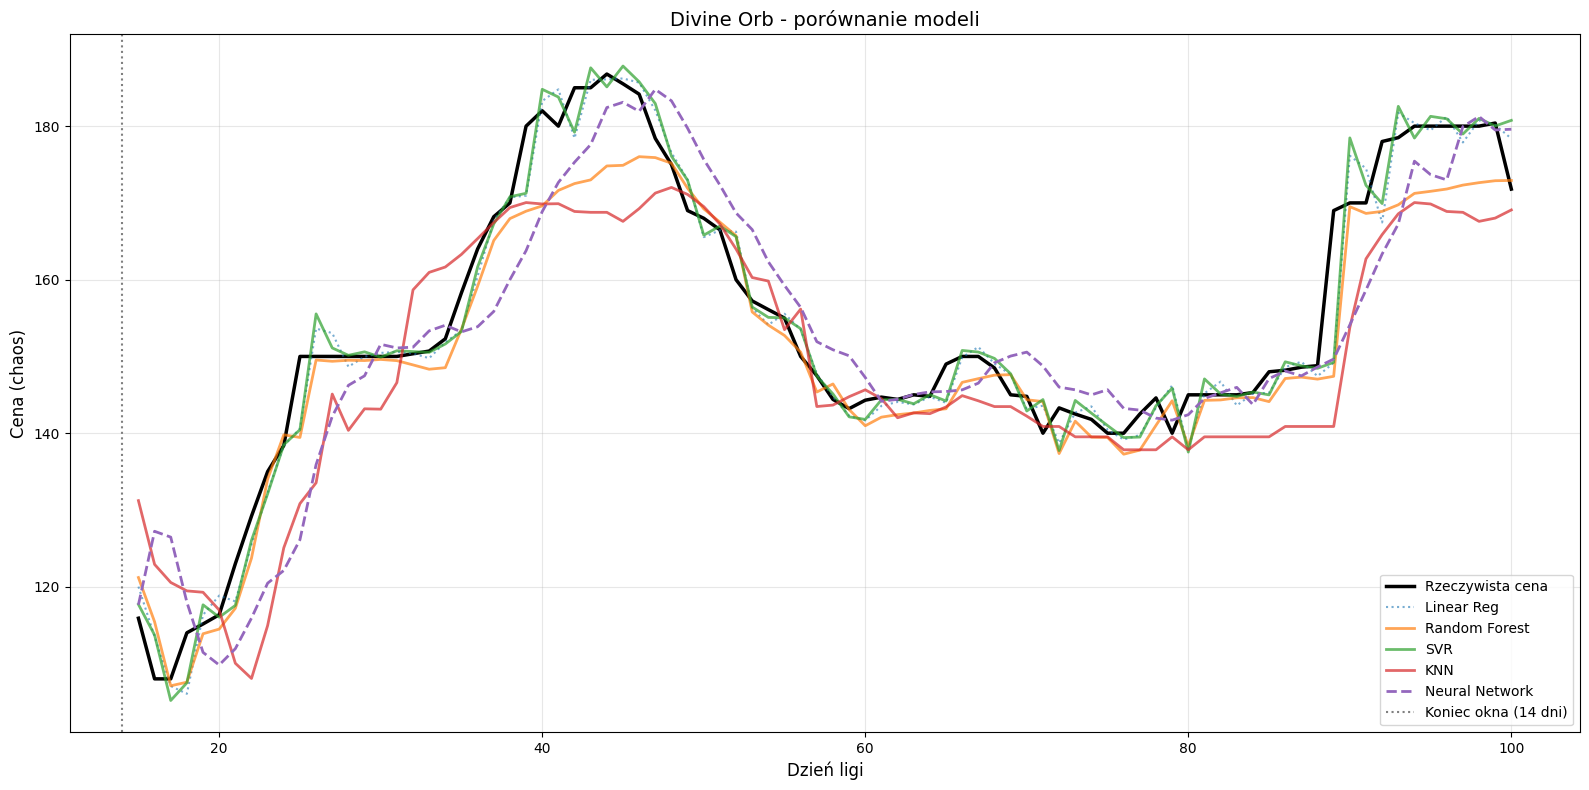

In [25]:
plt.figure(figsize=(16, 8))
days_total = range(1, WINDOW + len(actuals_nn) + 1)
days_preds = range(WINDOW + 1, WINDOW + len(actuals_nn) + 1)
test_prices = actuals_nn
plt.plot(days_preds, test_prices, label='Rzeczywista cena', color='black', lw=2.5)
plt.plot(days_preds, preds_lr, label='Linear Reg', alpha=0.6, linestyle=':')
plt.plot(days_preds, preds_rf, label='Random Forest', alpha=0.7, linewidth=2)
plt.plot(days_preds, preds_svr, label='SVR', alpha=0.7, linewidth=2)
plt.plot(days_preds, preds_knn, label='KNN', alpha=0.7, linewidth=2)
plt.plot(days_preds, preds_nn, label='Neural Network', linestyle='--', linewidth=2)
plt.axvline(x=WINDOW, color='gray', linestyle=':', label=f'Koniec okna ({WINDOW} dni)')
plt.title(f'{ITEM} - porównanie modeli', fontsize=14)
plt.xlabel('Dzień ligi', fontsize=12)
plt.ylabel('Cena (chaos)', fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


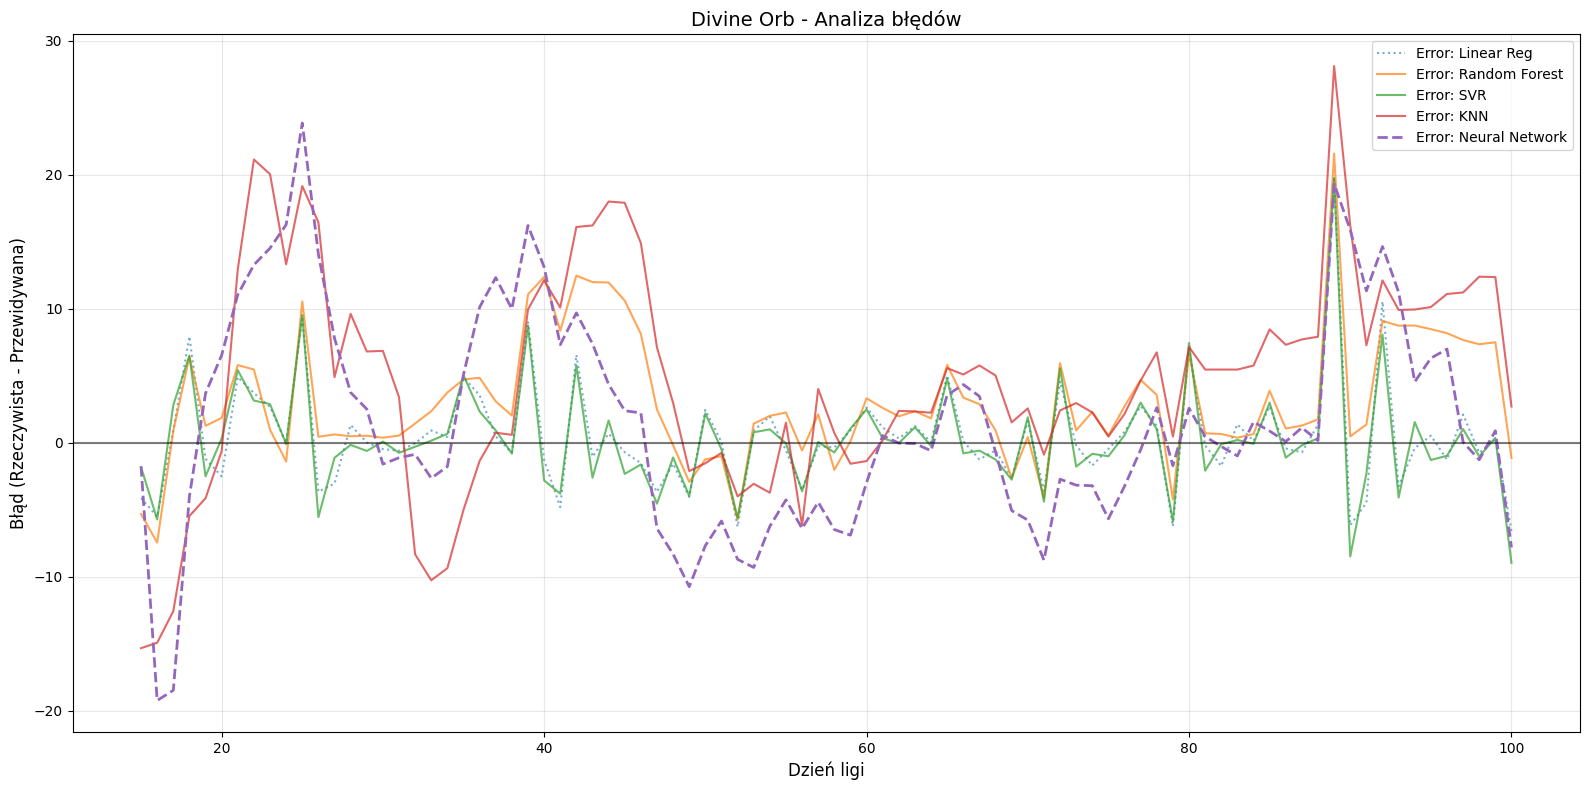

In [26]:
plt.figure(figsize=(16, 8))

days_preds = range(WINDOW + 1, WINDOW + len(actuals_nn) + 1)

plt.plot(days_preds, actuals_nn - preds_lr, label='Error: Linear Reg', alpha=0.6, linestyle=':')
plt.plot(days_preds, actuals_nn - preds_rf, label='Error: Random Forest', alpha=0.7)
plt.plot(days_preds, actuals_nn - preds_svr, label='Error: SVR', alpha=0.7)
plt.plot(days_preds, actuals_nn - preds_knn, label='Error: KNN', alpha=0.7)
plt.plot(days_preds, actuals_nn - preds_nn, label='Error: Neural Network', linestyle='--', linewidth=2)

plt.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.5)

plt.title(f'{ITEM} - Analiza błędów', fontsize=14)
plt.xlabel('Dzień ligi', fontsize=12)
plt.ylabel('Błąd (Rzeczywista - Przewidywana)', fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()